# 02 — Bureau EDA

Exploratory analysis of `bureau.csv` and `bureau_balance.csv`: external credit-bureau history linked to Home Credit applications.

## Purpose

This notebook answers bureau-domain questions before feature engineering:

- What is the grain, schema, missingness, and cardinality of bureau credits and monthly balance snapshots?
- Are `SK_ID_CURR` / `SK_ID_BUREAU` complete and joinable?
- How much of train/test is covered by bureau history, and how complete is `bureau_balance` coverage of bureau credits?
- What do credit status, credit type, overdue fields, and monthly `STATUS` look like?

**Context:** [00_dataset_overview.ipynb](00_dataset_overview.ipynb) · [01_application_eda.ipynb](01_application_eda.ipynb) · [docs/glossary.md](../../docs/glossary.md) · `data/HomeCredit_columns_description.csv`

## Out of scope

- Credit scoring model training
- Null-importance feature selection
- Fairness metrics / mitigation → later pipeline


## 0. Load and shape

Load bureau and bureau_balance, then report rows, columns, memory, primary keys, and table grain.


In [6]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_rows", 50)
pd.set_option("display.max_colwidth", 100)

HIGH_MISSINGNESS_THRESHOLD = 0.50
BUREAU_KEYS = ["SK_ID_CURR", "SK_ID_BUREAU"]
BALANCE_KEYS = ["SK_ID_BUREAU", "MONTHS_BALANCE"]

_cwd = Path.cwd()
if not (_cwd / "data" / "bureau.csv").exists():
    repo_root = (_cwd / "../..").resolve()
    if (repo_root / "data" / "bureau.csv").exists():
        os.chdir(repo_root)
    else:
        raise FileNotFoundError(
            "Place Home Credit CSVs in data/ and run with repo root or analysis/notebooks/ as cwd."
        )

DATA_DIR = Path("data")


def load_csv(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}")
    return pd.read_csv(path)


bureau = load_csv(DATA_DIR / "bureau.csv")
bureau_balance = load_csv(DATA_DIR / "bureau_balance.csv")
app_train = load_csv(DATA_DIR / "application_train.csv")[["SK_ID_CURR", "TARGET"]]
app_test = load_csv(DATA_DIR / "application_test.csv")[["SK_ID_CURR"]]

shape_rows = []
for name, df, grain, keys in [
    ("bureau", bureau, "One row per previous Credit Bureau credit", BUREAU_KEYS),
    ("bureau_balance", bureau_balance, "One row per bureau credit per monthly status snapshot", BALANCE_KEYS),
]:
    shape_rows.append(
        {
            "table": name,
            "rows": len(df),
            "columns": df.shape[1],
            "keys": ", ".join(keys),
            "grain": grain,
        }
    )

shape_summary = pd.DataFrame(shape_rows)
display(shape_summary.style.hide(axis="index"))

print("Sample rows from bureau:")
display(bureau.head(3))
print("Sample rows from bureau_balance:")
display(bureau_balance.head(3))


table,rows,columns,keys,grain
bureau,1716428,17,"SK_ID_CURR, SK_ID_BUREAU",One row per previous Credit Bureau credit
bureau_balance,27299925,3,"SK_ID_BUREAU, MONTHS_BALANCE",One row per bureau credit per monthly status snapshot


Sample rows from bureau:


,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
0,215354,5714462,Closed,currency 1,-497,0,-153.0,-153.0,NaN,0,91323.0,0.0,NaN,0.0,Consumer credit,-131,NaN
1,215354,5714463,Active,currency 1,-208,0,1075.0,NaN,NaN,0,225000.0,171342.0,NaN,0.0,Credit card,-20,NaN
2,215354,5714464,Active,currency 1,-203,0,528.0,NaN,NaN,0,464323.5,NaN,NaN,0.0,Consumer credit,-16,NaN


Sample rows from bureau_balance:


,SK_ID_BUREAU,MONTHS_BALANCE,STATUS
0,5715448,0,C
1,5715448,-1,C
2,5715448,-2,C


## 1. Schema & Missignes

Inspect dtypes and look up ambiguous column meanings in `data/HomeCredit_columns_description.csv`.


In [2]:
def schema_summary(df: pd.DataFrame, table_name: str) -> pd.DataFrame:
    n = len(df)
    rows = []
    for col in df.columns:
        missing = int(df[col].isna().sum())
        n_unique = int(df[col].nunique(dropna=True))
        rows.append(
            {
                "table": table_name,
                "column": col,
                "dtype": str(df[col].dtype),
                "%missing": round(100 * missing / n, 2) if n else 0.0,
                "%unique": round(100 * n_unique / n, 2) if n else 0.0,
                "n_unique": n_unique,
            }
        )
    return pd.DataFrame(rows)


schema = pd.concat(
    [schema_summary(bureau, "bureau"), schema_summary(bureau_balance, "bureau_balance")],
    ignore_index=True,
)
display(schema.style.hide(axis="index").format({"%missing": "{:.2f}", "%unique": "{:.2f}"}))

table,column,dtype,%missing,%unique,n_unique
bureau,SK_ID_CURR,int64,0.00,17.82,305811
bureau,SK_ID_BUREAU,int64,0.00,100.00,1716428
bureau,CREDIT_ACTIVE,str,0.00,0.00,4
bureau,CREDIT_CURRENCY,str,0.00,0.00,4
bureau,DAYS_CREDIT,int64,0.00,0.17,2923
bureau,CREDIT_DAY_OVERDUE,int64,0.00,0.05,942
bureau,DAYS_CREDIT_ENDDATE,float64,6.15,0.82,14096
bureau,DAYS_ENDDATE_FACT,float64,36.92,0.17,2917
bureau,AMT_CREDIT_MAX_OVERDUE,float64,65.51,3.98,68251
bureau,CNT_CREDIT_PROLONG,int64,0.00,0.00,10


Note: the description file names the bureau key `SK_BUREAU_ID`, while the CSV column is `SK_ID_BUREAU`. Treat them as the same join key.

**High missingness** concentrates in bureau amount fields (`AMT_ANNUITY`, `AMT_CREDIT_MAX_OVERDUE`) and some closed-credit / limit fields. `bureau_balance` has no missing values. 



## 2. Cardinality and numeric summaries

See how many distinct values categorical columns take, and skim numeric ranges for scale or anomaly checks.


In [ ]:
cat_cols = bureau.select_dtypes(include=["object", "string"]).columns.tolist()
cardinality = (
    bureau[cat_cols]
    .nunique(dropna=True)
    .sort_values(ascending=False)
    .rename("n_unique")
    .reset_index()
    .rename(columns={"index": "column"})
)
print("Unique values per categorical column:")
display(cardinality.style.hide(axis="index"))

for col in cat_cols:
    counts = bureau[col].value_counts(dropna=False).head(15).rename("count").reset_index()
    counts.columns = [col, "count"]
    print(f"Unique values and countsin {col}:")
    display(counts.style.hide(axis="index"))


Unique values per categorical column:


column,n_unique
CREDIT_TYPE,15
CREDIT_ACTIVE,4
CREDIT_CURRENCY,4


Unique values and countsin CREDIT_ACTIVE:


CREDIT_ACTIVE,count
Closed,1079273
Active,630607
Sold,6527
Bad debt,21


Unique values and countsin CREDIT_CURRENCY:


CREDIT_CURRENCY,count
currency 1,1715020
currency 2,1224
currency 3,174
currency 4,10


Unique values and countsin CREDIT_TYPE:


CREDIT_TYPE,count
Consumer credit,1251615
Credit card,402195
Car loan,27690
Mortgage,18391
Microloan,12413
Loan for business development,1975
Another type of loan,1017
Unknown type of loan,555
Loan for working capital replenishment,469
Cash loan (non-earmarked),56


`CREDIT_ACTIVE` is dominated by Closed/Active; Bad debt is extremely rare. Most credits are Consumer credit or Credit card. A small number of day-offset values fall outside a ~100-year window (especially `DAYS_CREDIT_ENDDATE`) — worth clipping or flagging in FE rather than treating as real tenure.

### Summarize count, mean, and spread for numeric bureau columns 
xExtreme min/max values can flag sentinels or data-entry issues.


In [4]:
numeric_cols = [c for c in bureau.select_dtypes(include=[np.number]).columns if c not in BUREAU_KEYS]
numeric_summary = bureau[numeric_cols].describe().T
numeric_summary["missing_pct"] = (100 * bureau[numeric_cols].isna().mean()).round(2)
print("Numeric summary in bureau:")
display(numeric_summary.round(2))

# Flag implausible day offsets beyond ~100 years
DAY_COLS = ["DAYS_CREDIT", "DAYS_CREDIT_ENDDATE", "DAYS_ENDDATE_FACT", "DAYS_CREDIT_UPDATE"]
extreme_rows = []
for col in DAY_COLS:
    s = bureau[col]
    extreme_mask = s.notna() & ((s < -365 * 100) | (s > 365 * 100))
    extreme_rows.append(
        {
            "column": col,
            "extreme_count": int(extreme_mask.sum()),
            "extreme_pct": round(100 * extreme_mask.mean(), 4),
            "min": s.min(),
            "max": s.max(),
        }
    )
extreme_days = pd.DataFrame(extreme_rows)
print("Extreme day offsets:")
display(extreme_days.style.hide(axis="index"))


Numeric summary in bureau:


,count,mean,std,min,25%,50%,75%,max,missing_pct
DAYS_CREDIT,1716428.0,-1142.11,795.16,-2922.00,-1666.0,-987.0,-474.0,0.000000e+00,0.00
CREDIT_DAY_OVERDUE,1716428.0,0.82,36.54,0.00,0.0,0.0,0.0,2.792000e+03,0.00
DAYS_CREDIT_ENDDATE,1610875.0,510.52,4994.22,-42060.00,-1138.0,-330.0,474.0,3.119900e+04,6.15
DAYS_ENDDATE_FACT,1082775.0,-1017.44,714.01,-42023.00,-1489.0,-897.0,-425.0,0.000000e+00,36.92
AMT_CREDIT_MAX_OVERDUE,591940.0,3825.42,206031.61,0.00,0.0,0.0,0.0,1.159872e+08,65.51
CNT_CREDIT_PROLONG,1716428.0,0.01,0.10,0.00,0.0,0.0,0.0,9.000000e+00,0.00
AMT_CREDIT_SUM,1716415.0,354994.59,1149811.34,0.00,51300.0,125518.5,315000.0,5.850000e+08,0.00
AMT_CREDIT_SUM_DEBT,1458759.0,137085.12,677401.13,-4705600.32,0.0,0.0,40153.5,1.701000e+08,15.01
AMT_CREDIT_SUM_LIMIT,1124648.0,6229.51,45032.03,-586406.12,0.0,0.0,0.0,4.705600e+06,34.48
AMT_CREDIT_SUM_OVERDUE,1716428.0,37.91,5937.65,0.00,0.0,0.0,0.0,3.756681e+06,0.00


Extreme day offsets:


column,extreme_count,extreme_pct,min,max
DAYS_CREDIT,0,0.000000,-2922.000000,0.000000
DAYS_CREDIT_ENDDATE,134,0.007800,-42060.000000,31199.000000
DAYS_ENDDATE_FACT,1,0.000100,-42023.000000,0.000000
DAYS_CREDIT_UPDATE,95,0.005500,-41947.000000,372.000000


`AMT_CREDIT_SUM_DEBT` and `AMT_CREDIT_SUM_LIMIT` have some negative values. These are uncommon but should be inspected or clipped in FE so they do not distort client-level sums. Likely credit-card balance/limit sign convention (sometimes mirrored), not a reason to distrust all bureau amounts.


## 3. Coverage and joins

Measure how many application clients have bureau credits, and how many bureau credits have monthly balance history.


In [7]:
train_ids = set(app_train["SK_ID_CURR"])
test_ids = set(app_test["SK_ID_CURR"])
bureau_client_ids = set(bureau["SK_ID_CURR"])
bureau_credit_ids = set(bureau["SK_ID_BUREAU"])
balance_credit_ids = set(bureau_balance["SK_ID_BUREAU"])

coverage = pd.DataFrame(
    [
        {
            "split": "train",
            "clients": len(train_ids),
            "clients_with_bureau": len(train_ids & bureau_client_ids),
            "coverage_pct": round(100 * len(train_ids & bureau_client_ids) / len(train_ids), 2),
        },
        {
            "split": "test",
            "clients": len(test_ids),
            "clients_with_bureau": len(test_ids & bureau_client_ids),
            "coverage_pct": round(100 * len(test_ids & bureau_client_ids) / len(test_ids), 2),
        },
    ]
)
display(coverage.style.hide(axis="index").format({"coverage_pct": "{:.2f}"}))

join_quality = pd.DataFrame(
    [
        {
            "check": "bureau credits with balance history",
            "n": len(bureau_credit_ids & balance_credit_ids),
            "pct_of_bureau_credits": round(
                100 * len(bureau_credit_ids & balance_credit_ids) / len(bureau_credit_ids), 2
            ),
        },
        {
            "check": "balance credits found in bureau",
            "n": len(balance_credit_ids & bureau_credit_ids),
            "pct_of_balance_credits": round(
                100 * len(balance_credit_ids & bureau_credit_ids) / len(balance_credit_ids), 2
            ),
        },
        {
            "check": "bureau clients outside train/test",
            "n": len(bureau_client_ids - train_ids - test_ids),
            "pct_of_bureau_credits": np.nan,
        },
    ]
)
display(join_quality.style.hide(axis="index"))

credits_per_client = bureau.groupby("SK_ID_CURR").size()
credits_summary = credits_per_client.describe().rename("credits_per_client").to_frame().T
display(credits_summary.round(2))

# Default rate by bureau presence (train only) — descriptive, not a fairness metric
has_bureau = app_train["SK_ID_CURR"].isin(bureau_client_ids)
default_by_bureau = pd.DataFrame(
    {
        "group": ["has_bureau", "no_bureau"],
        "n_clients": [int(has_bureau.sum()), int((~has_bureau).sum())],
        "default_rate_pct": [
            round(100 * app_train.loc[has_bureau, "TARGET"].mean(), 2),
            round(100 * app_train.loc[~has_bureau, "TARGET"].mean(), 2),
        ],
    }
)
display(default_by_bureau.style.hide(axis="index"))


split,clients,clients_with_bureau,coverage_pct
train,307511,263491,85.69
test,48744,42320,86.82


check,n,pct_of_bureau_credits,pct_of_balance_credits
bureau credits with balance history,774354,45.110000,nan
balance credits found in bureau,774354,nan,94.730000
bureau clients outside train/test,0,nan,nan


,count,mean,std,min,25%,50%,75%,max
credits_per_client,305811.0,5.61,4.43,1.0,2.0,4.0,8.0,116.0


group,n_clients,default_rate_pct
has_bureau,263491,7.730000
no_bureau,44020,10.120000


- ~86% of train and test clients have at least one bureau credit.
- ~14% have no bureau history at all (“thin file”).
- Only ~45% of bureau credits have monthly balance rows. So balance-based features will be missing for many credits - I will may need a “has balance history” flag in credit scoring model
- ~95% of balance credit IDs match back to bureau (joins are mostly clean).
- 0 bureau clients sit outside train/test.
- Clients with bureau data have about 5–6 credits on average (median 4, max 116).
- One client → many bureau rows, so I will aggregate to SK_ID_CURR during feature engineering.
- With bureau: ~7.7% default rate (263k clients)
- Without bureau: ~10.1% default rate (44k clients)

**Clients without bureau history default more often in this raw comparison**. That’s descriptive only — not a model or fairness conclusion — but it’s worth noting for later FE and fairness audit.

## 4. Credit status and overdue signals

Inspect active/closed structure and how rare overdue fields are at application time.


In [9]:
active_counts = bureau["CREDIT_ACTIVE"].value_counts(dropna=False).rename("count").reset_index()
active_counts.columns = ["CREDIT_ACTIVE", "count"]
active_counts["pct"] = (100 * active_counts["count"] / len(bureau)).round(2)
display(active_counts.style.hide(axis="index"))

overdue_flags = pd.DataFrame(
    [
        {
            "signal": "CREDIT_DAY_OVERDUE > 0",
            "n_rows": int((bureau["CREDIT_DAY_OVERDUE"] > 0).sum()),
            "pct_rows": round(100 * (bureau["CREDIT_DAY_OVERDUE"] > 0).mean(), 3),
        },
        {
            "signal": "AMT_CREDIT_SUM_OVERDUE > 0",
            "n_rows": int((bureau["AMT_CREDIT_SUM_OVERDUE"].fillna(0) > 0).sum()),
            "pct_rows": round(100 * (bureau["AMT_CREDIT_SUM_OVERDUE"].fillna(0) > 0).mean(), 3),
        },
        {
            "signal": "CNT_CREDIT_PROLONG > 0",
            "n_rows": int((bureau["CNT_CREDIT_PROLONG"] > 0).sum()),
            "pct_rows": round(100 * (bureau["CNT_CREDIT_PROLONG"] > 0).mean(), 3),
        },
    ]
)
display(overdue_flags.style.hide(axis="index"))

# Client-level active credit counts for train clients with bureau history
active = bureau[bureau["CREDIT_ACTIVE"] == "Active"]
active_per_client = active.groupby("SK_ID_CURR").size()
active_summary = active_per_client.describe().rename("active_credits_per_client").to_frame().T
display(active_summary.round(2))


CREDIT_ACTIVE,count,pct
Closed,1079273,62.880000
Active,630607,36.740000
Sold,6527,0.380000
Bad debt,21,0.000000


signal,n_rows,pct_rows
CREDIT_DAY_OVERDUE > 0,4217,0.246000
AMT_CREDIT_SUM_OVERDUE > 0,4158,0.242000
CNT_CREDIT_PROLONG > 0,9114,0.531000


,count,mean,std,min,25%,50%,75%,max
active_credits_per_client,251815.0,2.5,1.67,1.0,1.0,2.0,3.0,32.0


Overdue fields are rare at the credit level (~0.25% of rows). 


## 5. Bureau balance history

Inspect monthly balance horizon and STATUS codes (C=closed, X=unknown, 0=no DPD, 1–5=DPD buckets).


In [10]:
status_counts = bureau_balance["STATUS"].value_counts(dropna=False).rename("count").reset_index()
status_counts.columns = ["STATUS", "count"]
status_counts["pct"] = (100 * status_counts["count"] / len(bureau_balance)).round(3)
display(status_counts.style.hide(axis="index"))

months_summary = bureau_balance["MONTHS_BALANCE"].describe().to_frame().T
display(months_summary.round(2))

history_len = bureau_balance.groupby("SK_ID_BUREAU").size()
history_summary = history_len.describe().rename("months_per_bureau_credit").to_frame().T
display(history_summary.round(2))

# Late-status share among balance rows (STATUS in 1-5)
late_mask = bureau_balance["STATUS"].isin(list("12345"))
late_summary = pd.DataFrame(
    [
        {
            "late_status_rows": int(late_mask.sum()),
            "late_status_pct": round(100 * late_mask.mean(), 3),
            "credits_with_any_late": int(
                bureau_balance.loc[late_mask, "SK_ID_BUREAU"].nunique()
            ),
        }
    ]
)
display(late_summary.style.hide(axis="index"))


STATUS,count,pct
C,13646993,49.989000
0,7499507,27.471000
X,5810482,21.284000
1,242347,0.888000
5,62406,0.229000
2,23419,0.086000
3,8924,0.033000
4,5847,0.021000


,count,mean,std,min,25%,50%,75%,max
MONTHS_BALANCE,27299925.0,-30.74,23.86,-96.0,-46.0,-25.0,-11.0,0.0


,count,mean,std,min,25%,50%,75%,max
months_per_bureau_credit,817395.0,33.4,25.79,1.0,13.0,26.0,48.0,97.0


late_status_rows,late_status_pct,credits_with_any_late
342943,1.256000,103264


`MONTHS_BALANCE` spans 0 to −96 (~8 years). Most monthly statuses are Closed (`C`). DPD statuses 1–5 are uncommon but useful for delinquency features once aggregated to credit and then to client.


## 6. Plots

Visualize the most important bureau and balance distributions for quick inspection.


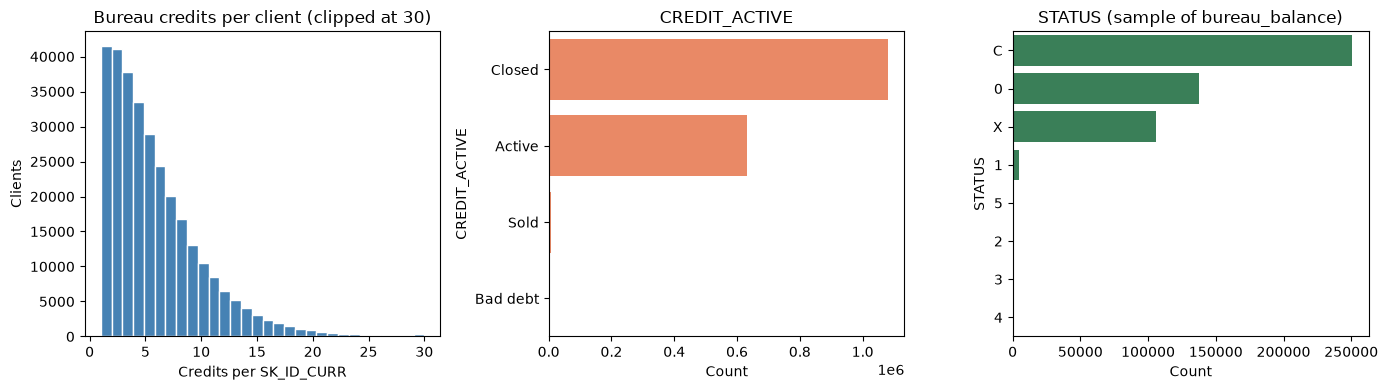

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Credits per client (cap for readability)
credits_per_client = bureau.groupby("SK_ID_CURR").size()
axes[0].hist(credits_per_client.clip(upper=30), bins=30, color="steelblue", edgecolor="white")
axes[0].set_title("Bureau credits per client (clipped at 30)")
axes[0].set_xlabel("Credits per SK_ID_CURR")
axes[0].set_ylabel("Clients")

# CREDIT_ACTIVE
active_order = bureau["CREDIT_ACTIVE"].value_counts().index
sns.countplot(data=bureau, y="CREDIT_ACTIVE", order=active_order, ax=axes[1], color="coral")
axes[1].set_title("CREDIT_ACTIVE")
axes[1].set_xlabel("Count")

# STATUS in bureau_balance
status_order = bureau_balance["STATUS"].value_counts().index
sns.countplot(
    data=bureau_balance.sample(n=min(500_000, len(bureau_balance)), random_state=42),
    y="STATUS",
    order=status_order,
    ax=axes[2],
    color="seagreen",
)
axes[2].set_title("STATUS (sample of bureau_balance)")
axes[2].set_xlabel("Count")

plt.tight_layout()
plt.show()


## 7. FE / join / leakage notes

Capture implications for later feature engineering without building the model here.


In [12]:
# Example client-level aggregates that FE may compute later (preview only)
bureau_fe_preview = (
    bureau.groupby("SK_ID_CURR")
    .agg(
        bureau_credit_count=("SK_ID_BUREAU", "count"),
        bureau_active_count=("CREDIT_ACTIVE", lambda s: (s == "Active").sum()),
        bureau_avg_days_credit=("DAYS_CREDIT", "mean"),
        bureau_max_overdue_days=("CREDIT_DAY_OVERDUE", "max"),
        bureau_sum_debt=("AMT_CREDIT_SUM_DEBT", "sum"),
    )
    .reset_index()
)
display(bureau_fe_preview.head(5).style.hide(axis="index"))

# Balance late-status rate per credit (preview), then note join path: balance -> bureau -> SK_ID_CURR
late_by_credit = (
    bureau_balance.assign(is_late=bureau_balance["STATUS"].isin(list("12345")))
    .groupby("SK_ID_BUREAU")["is_late"]
    .mean()
    .rename("late_month_rate")
    .reset_index()
)
display(late_by_credit.head(5).style.hide(axis="index"))


SK_ID_CURR,bureau_credit_count,bureau_active_count,bureau_avg_days_credit,bureau_max_overdue_days,bureau_sum_debt
100001,7,3,-735.000000,0,596686.500000
100002,8,2,-874.000000,0,245781.000000
100003,4,1,-1400.750000,0,0.000000
100004,2,0,-867.000000,0,0.000000
100005,3,2,-190.666667,0,568408.500000


SK_ID_BUREAU,late_month_rate
5001709,0.000000
5001710,0.000000
5001711,0.000000
5001712,0.000000
5001713,0.000000


**Join path for FE:** `bureau_balance` aggregates on `SK_ID_BUREAU` → merge to `bureau` → aggregate to `SK_ID_CURR` → merge to application.

**Leakage caution:** Day fields are relative to the current application date, which is appropriate. Do not use post-application outcomes. `CREDIT_ACTIVE == Bad debt` and DPD statuses are historical bureau signals available at application time according to the data dictionary, but treat rare labels carefully and validate temporal definitions in FE.

**Fairness / proxy note:** Bureau presence itself is associated with different default rates in train. Missing bureau history may correlate with thinner credit files or socioeconomic factors; audit later in `07_protected_attributes.ipynb` rather than treating presence as a protected attribute.


## Summary of findings

_Executed successfully on 2026-07-16._

- **Grain / keys:** `bureau` is 1,716,428 credits × 17 columns (~496 MB); `SK_ID_BUREAU` is unique with no nulls. `bureau_balance` is 27,299,925 monthly rows × 3 columns (~1.8 GB); unique on (`SK_ID_BUREAU`, `MONTHS_BALANCE`) with no nulls.
- **Missingness:** Two bureau columns exceed 50% missing — `AMT_ANNUITY` (71.5%) and `AMT_CREDIT_MAX_OVERDUE` (65.5%). Closed-credit / limit fields also have substantial missingness. `bureau_balance` has zero missing values.
- **Coverage:** ~85.7% of train and ~86.8% of test clients have at least one bureau credit. Clients with no bureau history have a higher raw train default rate (~10.1% vs ~7.7%). Only ~45% of bureau credits have monthly balance history; ~95% of distinct balance credit IDs join back to `bureau`.
- **Status / type:** Credits are mostly Closed (~63%) or Active (~37%); Bad debt is tiny. Dominant types are Consumer credit and Credit card. Currency is almost entirely `currency 1`.
- **Overdue rarity:** `CREDIT_DAY_OVERDUE > 0` on ~0.25% of bureau rows. In balance history, DPD statuses `1`–`5` are ~1.3% of months but appear on ~103k credits — useful after aggregation.
- **Anomalies:** A few `DAYS_*` values sit outside a ~100-year window (notably `DAYS_CREDIT_ENDDATE`). Some negative `AMT_CREDIT_SUM_DEBT` / `AMT_CREDIT_SUM_LIMIT` values exist; FE should clip or flag them.
- **Balance horizon:** `MONTHS_BALANCE` ranges from 0 to −96; median history length per credit with balances is 26 months.
- **FE implications:** Aggregate bureau to `SK_ID_CURR` (counts, active share, debt sums, max overdue). Aggregate `bureau_balance` to `SK_ID_BUREAU` first (late-month rate, recent STATUS), then to client. Add indicators for missing bureau history and missing balance history.
- **Leakage / fairness notes:** Day fields are application-relative (appropriate). Bureau presence itself is associated with different default rates and may relate to thin-file / socioeconomic factors — audit later in `07_protected_attributes.ipynb`, do not treat as a model protected-attribute feature here.
